# ChurnGuard: Exploratory Data Analysis

**Business question.** Which telecom customers are about to cancel, and what makes them leave?

**Dataset.** IBM Telco Customer Churn: one row per customer with demographics, the services they use,
their contract and billing details, and whether they left in the last month (`Churn`).

This notebook answers four questions before any modelling:
1. How big is the churn problem and how imbalanced is the target?
2. Are there data-quality issues to fix?
3. Which customer attributes are most associated with churn?
4. What does that mean for feature engineering and model choice?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from churnguard.data import clean, load_raw

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

Matplotlib is building the font cache; this may take a moment.


## 1. Load the raw data

In [2]:
raw = load_raw(ROOT / "data" / "raw" / "telco_churn.csv")
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


## 2. Data quality checks

In [3]:
blank_total = (raw["TotalCharges"].str.strip() == "")
print("Duplicate customer IDs:", raw["customerID"].duplicated().sum())
print("Blank TotalCharges:", blank_total.sum())
raw.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Duplicate customer IDs: 0
Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20,,No
5218,2923-ARZLG,0,19.7,,No
6670,4075-WKNIU,0,73.35,,No


**Insight.** There are no duplicate customers. `TotalCharges` is stored as text and is blank for **11 customers, all with tenure 0**. These are brand-new customers who have not received a bill yet, so the correct value is **0**, not the column mean. `clean()` applies exactly this rule, and `validate()` rejects unknown categories and negative numbers.

In [4]:
df = clean(raw)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   Int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. How big is the churn problem?

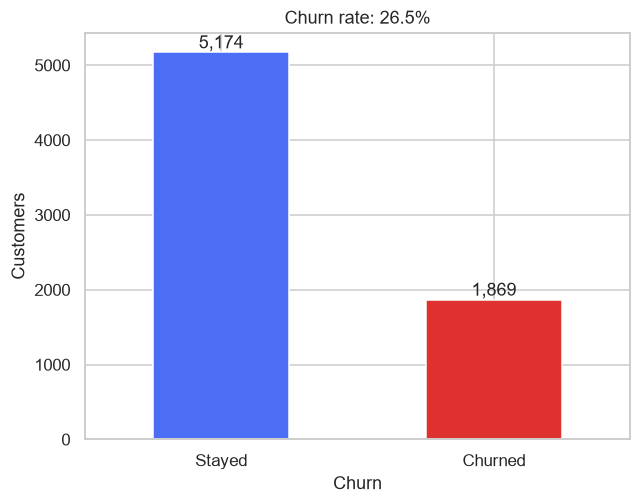

In [5]:
rate = df["Churn"].mean()
ax = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(color=["#4c6ef5", "#e03131"], rot=0)
ax.set(title=f"Churn rate: {rate:.1%}", ylabel="Customers")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

**Insight.** **1,869 of 7,043 customers (26.5%) churned.** The target is imbalanced. A model that always predicts "stays" would be 73.5% accurate and completely useless, so accuracy is the wrong metric. I use a stratified split, class weights, and ROC-AUC, PR-AUC and recall instead.

## 4. Contract, tenure and payment: the biggest signals

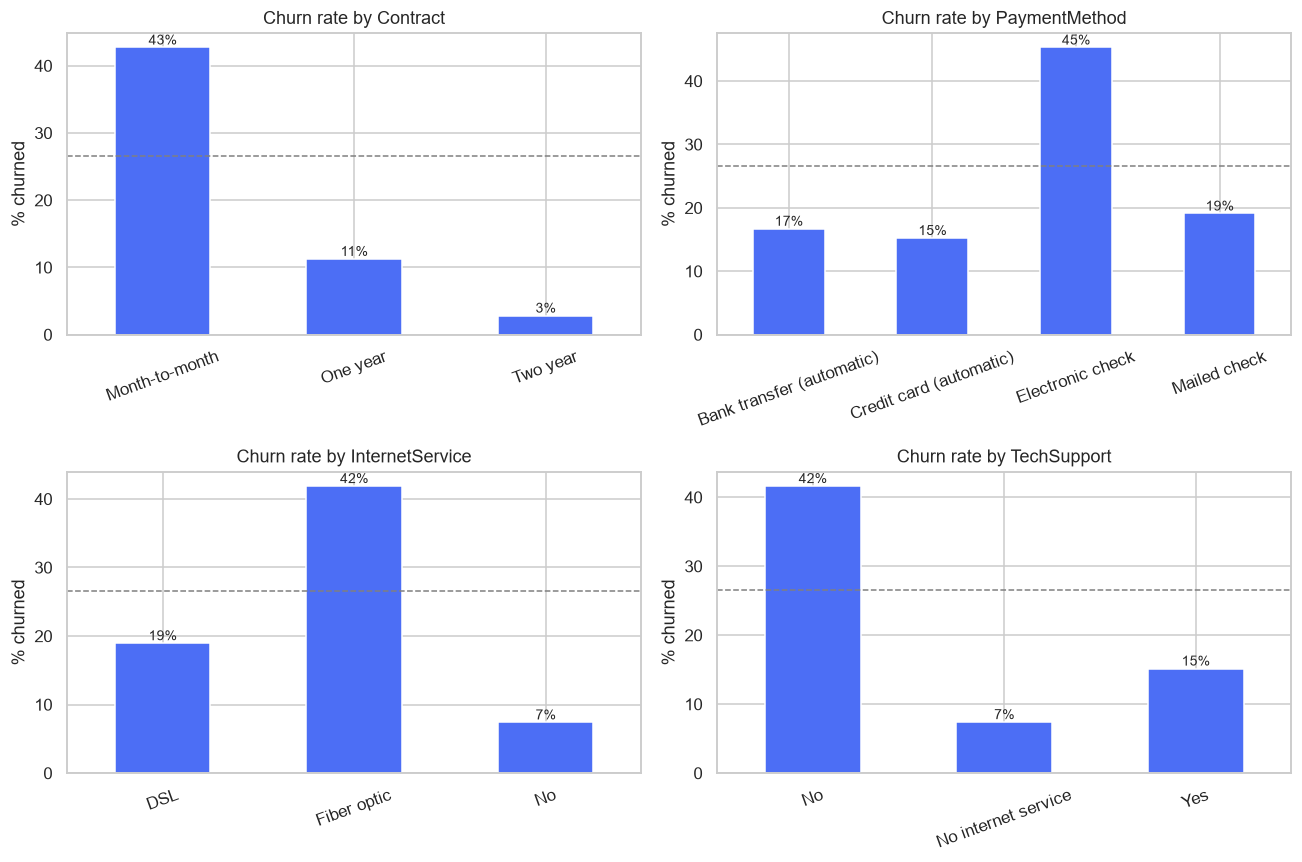

In [6]:
def churn_rate_by(col, ax, order=None):
    data = df.groupby(col)["Churn"].mean().mul(100)
    if order is not None:
        data = data.reindex(order)
    data.plot.bar(ax=ax, color="#4c6ef5", rot=20)
    ax.axhline(rate * 100, ls="--", color="grey", lw=1)
    ax.set(title=f"Churn rate by {col}", ylabel="% churned", xlabel="")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
churn_rate_by("Contract", axes[0, 0])
churn_rate_by("PaymentMethod", axes[0, 1])
churn_rate_by("InternetService", axes[1, 0])
churn_rate_by("TechSupport", axes[1, 1])
plt.tight_layout(); plt.show()

**Insights** (dashed line = overall churn rate of 26.5%):
- **Contract is the strongest signal.** Month-to-month customers churn at **42.7%**, one-year at 11.3%, two-year at only **2.8%**.
- **Electronic check** payers churn at **45.3%**, roughly three times the rate of automatic payments (15–17%). This motivates the `auto_payment` feature.
- **Fiber optic** customers churn at **41.9%** versus 19.0% for DSL, despite fiber being the premium product. This suggests a price or service-quality problem worth raising with the business.
- Customers **without tech support** (41.6%) or **online security** (41.8%) churn far more than those with it (about 15%). These add-ons look like retention levers.
- Gender makes no difference (26.9% vs 26.2%).

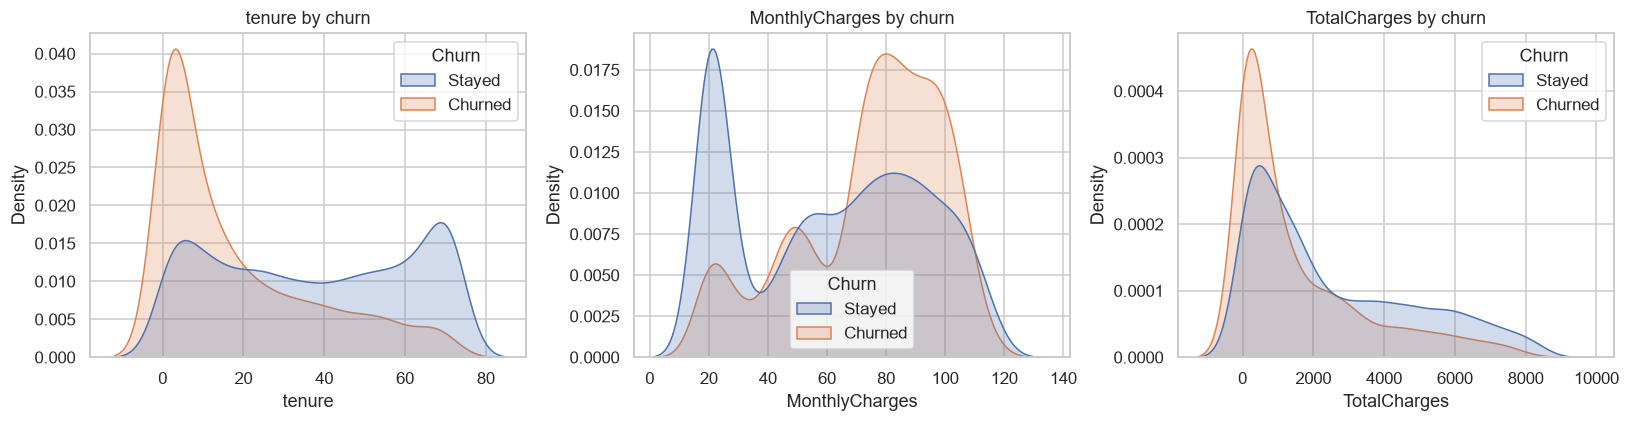

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df, x=col, hue=df["Churn"].map({0: "Stayed", 1: "Churned"}), common_norm=False, fill=True, ax=ax)
    ax.set(title=f"{col} by churn")
plt.tight_layout(); plt.show()

**Insight.** Churners are concentrated at **low tenure** (median 10 months vs 38 for customers who stay) and **higher monthly charges** (median $79.65 vs $64.43). Low `TotalCharges` among churners is mostly a consequence of short tenure, not a separate cause.

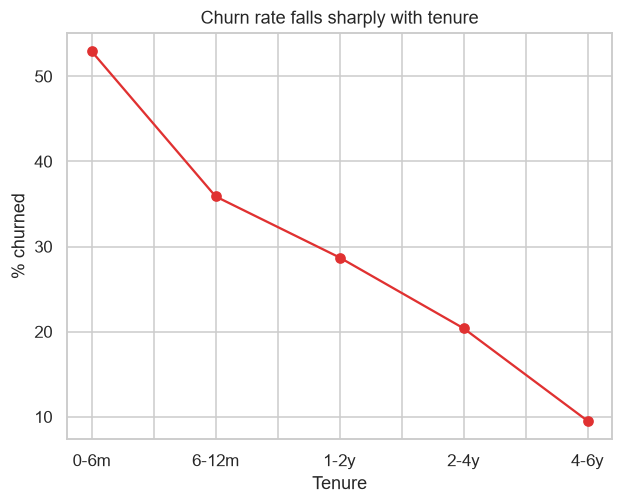

tenure
0-6m     52.9
6-12m    35.9
1-2y     28.7
2-4y     20.4
4-6y      9.5
Name: Churn, dtype: float64

In [8]:
bins = [-1, 6, 12, 24, 48, 72]
labels = ["0-6m", "6-12m", "1-2y", "2-4y", "4-6y"]
tenure_rate = df.groupby(pd.cut(df["tenure"], bins, labels=labels), observed=True)["Churn"].mean().mul(100)
ax = tenure_rate.plot(marker="o", color="#e03131")
ax.set(title="Churn rate falls sharply with tenure", ylabel="% churned", xlabel="Tenure")
plt.show()
tenure_rate.round(1)

**Insight.** Churn falls steadily with tenure: **52.9%** in the first 6 months, 35.9% at 6–12 months, and only **9.5%** after 4 years. The first year is the danger zone, so onboarding matters. The relationship is non-linear, which motivates the `tenure_bucket` feature and favours tree models.

## 5. Interactions: contract x tenure

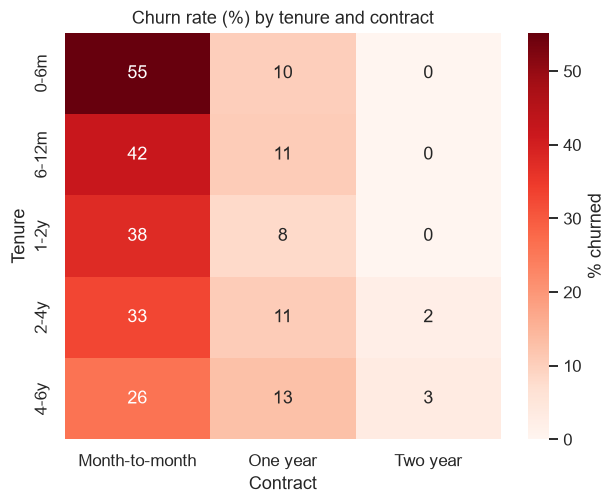

In [9]:
pivot = df.pivot_table(index=pd.cut(df["tenure"], bins, labels=labels), columns="Contract", values="Churn", aggfunc="mean", observed=True).mul(100)
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% churned"})
plt.title("Churn rate (%) by tenure and contract"); plt.ylabel("Tenure"); plt.show()

**Insight.** The contract effect holds at every tenure level. New month-to-month customers churn at **55%**, while two-year customers almost never churn, even when new. Contract and tenure interact, which tree-based models capture automatically.

## 6. Number of services

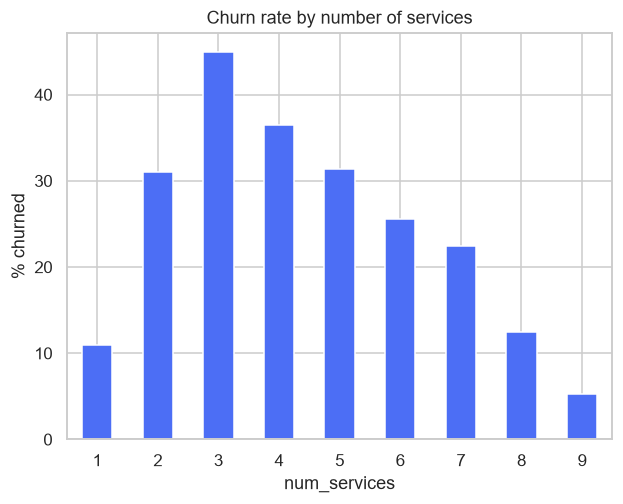

In [10]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_services"] = (df[services] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
ax = df.groupby("num_services")["Churn"].mean().mul(100).plot.bar(color="#4c6ef5", rot=0)
ax.set(title="Churn rate by number of services", ylabel="% churned")
plt.show()

**Insight.** The relationship is **not monotonic**: churn peaks at about 3 services (44.9%) and then falls to 5.3% for customers with 9. Customers with a single service are mostly phone-only and low-risk. A linear model cannot represent this shape directly, which is another reason to compare against tree models.

## 7. Correlation of numeric features

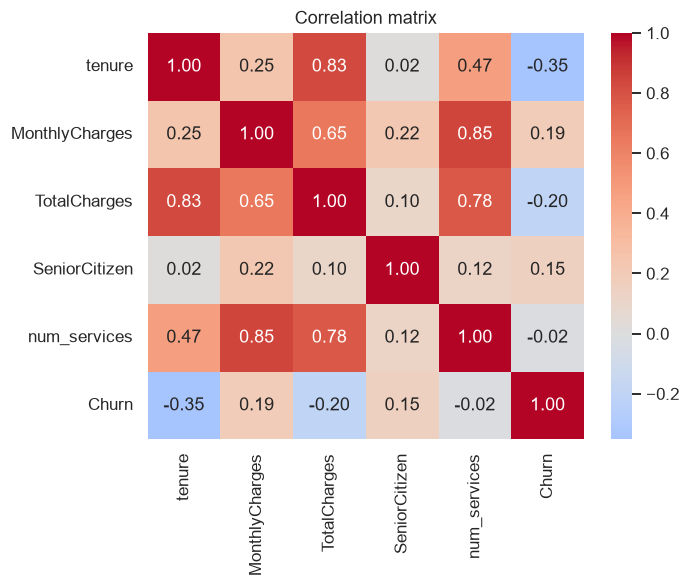

In [11]:
numeric = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "num_services", "Churn"]].astype(float)
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

**Insight.** `tenure` has the strongest linear correlation with churn (**-0.35**). `tenure` and `TotalCharges` are highly correlated (**0.83**), since total charges grow with time. This multicollinearity matters for interpreting Logistic Regression coefficients and for SHAP (correlated features share credit), but not for prediction quality.

## 8. Summary and decisions for modelling

**What EDA tells the model:**
1. **Imbalanced target (26.5%)**: stratify splits, use class weights, evaluate with ROC-AUC, PR-AUC and recall, and tune the decision threshold.
2. **Fix `TotalCharges`**: 11 blanks become 0 for tenure-0 customers.
3. **Strongest signals**: contract type, tenure, payment method, internet type, and the security and support add-ons.
4. **Engineered features**: `tenure_bucket`, `auto_payment`, `num_services`, `avg_monthly_spend`, `charge_increase`.
5. **Non-linear effects and interactions** (tenure x contract, number of services) suggest tree models may help, so compare Logistic Regression with Random Forest and XGBoost.
6. **Business levers** to test: longer contracts, automatic payment, the first-year onboarding experience, and support/security bundles for fiber customers.

Next step: `python -m churnguard.train` (see `src/churnguard/train.py`).